# Compute phosphorylation change q-values  - May 20, 2016

In [1]:
%pylab inline
import qvalue, os
import pandas as pd
import numpy as np

Populating the interactive namespace from numpy and matplotlib


##Configure directories

In [2]:
phospho_file = os.path.join('..','..','phosphorylation-data-sets','McKenna2014','aggregated_replicateABC_tukey_orig.txt')

## Load the EGFR phosphorylation data
Use the version that has p-values for all pairs of time point comparisons from Tukey HSD test.  Want to account for all tests that were performed, not the reduced set between the first and previous time points that are actually used later.  Columns of the form **tp2-tp1** are the p-value columns.

In [3]:
phospho_df = pd.read_csv(phospho_file, sep='\t')
print 'Loaded %d peptides' % (len(phospho_df))
print 'Data frame columns:'
print phospho_df.columns.values
phospho_df.head()

Loaded 1068 peptides
Data frame columns:
['peptide' 'protein' 'gene.name' 'minimum.tukey.p.value'
 'median.tukey.p.value' 'rep1.tp0' 'rep1.tp2' 'rep1.tp4' 'rep1.tp8'
 'rep1.tp16' 'rep1.tp32' 'rep1.tp64' 'rep1.tp128' 'rep2.tp0' 'rep2.tp2'
 'rep2.tp4' 'rep2.tp8' 'rep2.tp16' 'rep2.tp32' 'rep2.tp64' 'rep2.tp128'
 'rep3.tp0' 'rep3.tp2' 'rep3.tp4' 'rep3.tp8' 'rep3.tp16' 'rep3.tp32'
 'rep3.tp64' 'rep3.tp128' 'tp2-tp1' 'tp3-tp1' 'tp4-tp1' 'tp5-tp1' 'tp6-tp1'
 'tp7-tp1' 'tp8-tp1' 'tp3-tp2' 'tp4-tp2' 'tp5-tp2' 'tp6-tp2' 'tp7-tp2'
 'tp8-tp2' 'tp4-tp3' 'tp5-tp3' 'tp6-tp3' 'tp7-tp3' 'tp8-tp3' 'tp5-tp4'
 'tp6-tp4' 'tp7-tp4' 'tp8-tp4' 'tp6-tp5' 'tp7-tp5' 'tp8-tp5' 'tp7-tp6'
 'tp8-tp6' 'tp8-tp7' 'median.tp0' 'median.tp2' 'median.tp4' 'median.tp8'
 'median.tp16' 'median.tp32' 'median.tp64' 'median.tp128']


,peptide,protein,gene.name,minimum.tukey.p.value,median.tukey.p.value,rep1.tp0,rep1.tp2,rep1.tp4,rep1.tp8,rep1.tp16,...,tp8-tp6,tp8-tp7,median.tp0,median.tp2,median.tp4,median.tp8,median.tp16,median.tp32,median.tp64,median.tp128
0,-.n[305.21]MRK[432.30]ET[181.01]PPPLVPPAAR.E,"Q9BQA1,B4DJP0,B4DP38",WDR77,0.045053,0.874070,3.266944,2.848139,2.580626,3.058835,2.762461,...,0.965091,0.376328,2.76679,2.68569,2.42117,2.81289,2.12906,2.89894,2.79520,3.11382
1,-.n[305.21]MSTTAGY[243.03]LARR.A,Q96SA0,Putative uncharacterized protein,0.004737,0.730298,5.606161,4.002793,3.587753,3.832577,4.777530,...,0.028093,0.115603,7.69423,3.99119,3.82037,4.34460,4.75965,5.04384,5.77301,8.24482
2,K.n[305.21]AAASGQPRPEMQC[160.03]PAEHEEDMY[243....,Q96BN8,FAM105B,0.005700,0.755195,0.099820,0.861090,0.568702,0.498091,0.364445,...,0.992850,0.999629,0.10590,0.86109,0.56870,0.49809,0.36445,0.23328,0.15722,0.11192
3,K.n[305.21]AAGPAS[167.00]PPEEDPER.T,Q96KM6,ZNF512B,0.725082,0.998435,0.369111,0.760905,0.535401,0.586129,0.503314,...,0.999924,0.999968,0.70996,0.76090,0.74556,0.58613,0.65659,0.56510,0.70899,0.59856
4,K.n[305.21]AALGLQDS[167.00]DDEDAAVDIDEQIESMFNS...,"Q7L014,A8K6X3,D3DQA6",DDX46,0.001268,0.476125,5.980349,5.078731,4.807882,4.988418,4.692977,...,0.030959,0.091643,5.77342,5.13979,4.39768,4.98842,4.58252,4.63332,4.95409,5.95735


## Store only the p-value columns
Convert to a numpy data structure

In [4]:
# Retain all p-value columns in this range of column names
phospho_pvals_df = phospho_df.loc[:, 'tp2-tp1':'tp8-tp7']
print 'Filter data frame shape: %s' % str(phospho_pvals_df.shape)
phospho_pvals = phospho_pvals_df.values
print 'Numpy array shape: %s' % str(phospho_pvals.shape)
print 'Numpy array type: %s' % type(phospho_pvals)
phospho_pvals_df.head()

Filter data frame shape: (1068, 28)
Numpy array shape: (1068L, 28L)
Numpy array type: <type 'numpy.ndarray'>


,tp2-tp1,tp3-tp1,tp4-tp1,tp5-tp1,tp6-tp1,tp7-tp1,tp8-tp1,tp3-tp2,tp4-tp2,tp5-tp2,...,tp5-tp4,tp6-tp4,tp7-tp4,tp8-tp4,tp6-tp5,tp7-tp5,tp8-tp5,tp7-tp6,tp8-tp6,tp8-tp7
0,0.999811,0.484909,1.000000,0.374909,0.999975,0.976976,0.874649,0.729535,0.999990,0.609189,...,0.452852,0.999659,0.991474,0.807205,0.241322,0.873491,0.045053,0.903082,0.965091,0.376328
1,0.207988,0.212137,0.296223,0.374641,0.695874,0.983827,0.423177,1.000000,0.999996,0.999847,...,1.000000,0.993330,0.764721,0.007275,0.998663,0.848833,0.009931,0.989551,0.028093,0.115603
2,0.005700,0.400535,0.389710,0.746805,0.990944,0.999436,1.000000,0.259488,0.267745,0.097274,...,0.997489,0.824123,0.671688,0.405535,0.990043,0.948843,0.763585,0.999987,0.992850,0.999629
3,0.999995,0.999996,0.998033,0.987489,0.963331,0.999972,0.997236,1.000000,0.984840,0.998549,...,0.820275,0.725082,0.976897,0.898581,0.999999,0.999349,0.999999,0.995613,0.999924,0.999968
4,0.738649,0.016827,0.189344,0.009719,0.218471,0.499859,0.932410,0.259542,0.939590,0.162795,...,0.685057,1.000000,0.995142,0.026200,0.631296,0.304613,0.001268,0.997939,0.030959,0.091643


## Compute q-values
Consider all tests of all peptides and all pairs of time points.  Let qvalue package estimate pi0.  Assess the similarity of the standard and low memory versions.

got pi0 > 1 (4.707) while estimating qvalues, setting it to 1
got pi0 > 1 (4.707) while estimating qvalues, setting it to 1
Max difference between standard and low memory: 0.000033


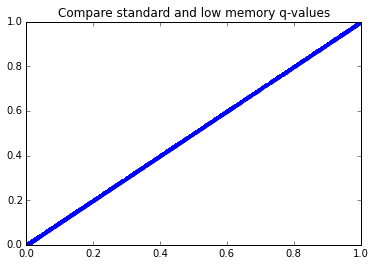

In [5]:
phospho_qvals = qvalue.estimate(phospho_pvals, verbose=True)
phospho_qvals_lm = qvalue.estimate(phospho_pvals, verbose=True, lowmem=True)

print 'Max difference between standard and low memory: %f' % max(abs(phospho_qvals.ravel()-phospho_qvals_lm))
plot(phospho_qvals.ravel(),phospho_qvals_lm,'.');
xlim(0,1);
ylim(0,1);
title('Compare standard and low memory q-values');

## Compare the original p-values and the q-values

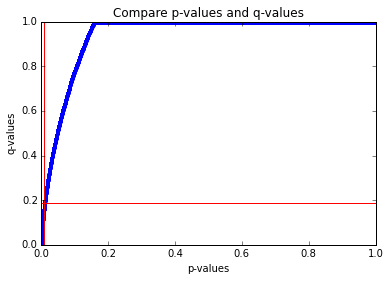

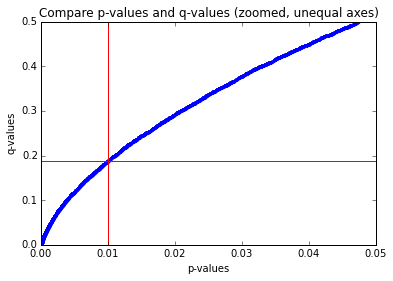

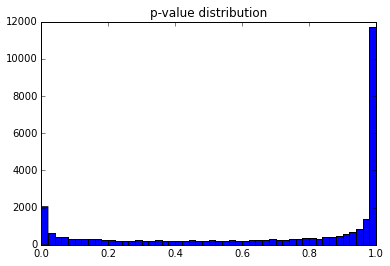

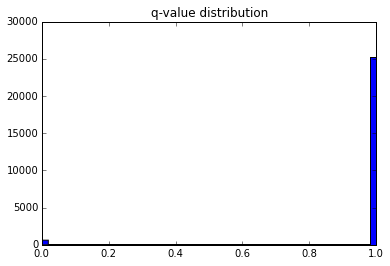

In [6]:
phospho_pvals_flat = phospho_pvals.ravel()
phospho_qvals_flat = phospho_qvals.ravel()

plot(phospho_pvals_flat,phospho_qvals_flat,'.');
# Draw a vertical line at the 0.01 p-value threshold we selected
# and the corresponding q-value thresold computed below
plot((0.01,0.01),(0,1),'r-')
plot((0,1),(0.188582,0.188582),'r-')
xlim(0,1);
ylim(0,1);
xlabel('p-values')
ylabel('q-values')
title('Compare p-values and q-values');

figure();
plot(phospho_pvals_flat,phospho_qvals_flat,'.');
# Draw a vertical line at the 0.01 p-value threshold we selected
# and the corresponding q-value thresold computed below
plot((0.01,0.01),(0,1),'r-')
plot((0,1),(0.188582,0.188582),'r-')
xlim(0,0.05);
ylim(0,0.5);
xlabel('p-values')
ylabel('q-values')
title('Compare p-values and q-values (zoomed, unequal axes)');

figure();
hist(phospho_pvals_flat, 50);
title('p-value distribution');

figure();
hist(phospho_qvals_flat, 50);
title('q-value distribution');

## Assess choice of p-value and q-value thresholds
p-value < 0.01 was the threshold used in the TPS manuscript.  Recall that this compares **all** p-values, not just those in the Tukey HSD columns that were of interest (comparison to the first and previous time point).

In [7]:
thresh = 0.01
print 'Select tests with p-value < %s' % str(thresh)
indices = phospho_pvals_flat < thresh
print '%d tests selected' % sum(indices)
print 'Max included q-value is %f' % max(phospho_qvals_flat[indices])
print 'Min excluded q-value is %f\n' % min(phospho_qvals_flat[~indices])

thresh = 0.05
print 'Select tests with p-value < %s' % str(thresh)
indices = phospho_pvals_flat < thresh
print '%d tests selected' % sum(indices)
print 'Max included q-value is %f' % max(phospho_qvals_flat[indices])
print 'Min excluded q-value is %f\n' % min(phospho_qvals_flat[~indices])

thresh = 0.1
print 'Select tests with q-value < %s' % str(thresh)
indices = phospho_qvals_flat < thresh
print '%d tests selected' % sum(indices)
print 'Max included p-value is %f' % max(phospho_pvals_flat[indices])
print 'Min excluded p-value is %f\n' % min(phospho_pvals_flat[~indices])

thresh = 0.2
print 'Select tests with q-value < %s' % str(thresh)
indices = phospho_qvals_flat < thresh
print '%d tests selected' % sum(indices)
print 'Max included p-value is %f' % max(phospho_pvals_flat[indices])
print 'Min excluded p-value is %f' % min(phospho_pvals_flat[~indices])

Select tests with p-value < 0.01
1587 tests selected
Max included q-value is 0.187762
Min excluded q-value is 0.188582

Select tests with p-value < 0.05
2887 tests selected
Max included q-value is 0.517827
Min excluded q-value is 0.518521

Select tests with q-value < 0.1
1131 tests selected
Max included p-value is 0.003781
Min excluded p-value is 0.003786

Select tests with q-value < 0.2
1641 tests selected
Max included p-value is 0.010969
Min excluded p-value is 0.010983
